In [132]:
# 1. 라이브러리 로드 및 시각화 환경 설정
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# 한글 폰트 설정 (Windows Malgun Gothic)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 35)
print('라이브러리 로드 완료')

라이브러리 로드 완료


In [133]:
# 2. 데이터셋 로드, 트레이드 중복 정리 및 대상 표본(시즌 >= 2019, mp >= 150) 필터링
df_raw = pd.read_csv('./Per 36 Minutes.csv')
print(f'원시 데이터 전체 크기: {df_raw.shape}')

# (1) 현대 농구 트렌드(포지션 파괴/스페이스 농구) 반영을 위한 2019 시즌 이후 데이터 필터링
df = df_raw[df_raw['season'] >= 2019].copy()
print(f'2019~2026 시즌 데이터 크기: {df.shape}')

# (2) 동일 시즌 트레이드(이적) 선수 중복 제거
# Basketball-Reference 특성상 한 시즌에 여러 팀으로 트레이드된 선수는
# 첫 행에 시즌 종합 합산(2TM/3TM 등)이 나오고, 그 뒤에 개별 팀별 행이 중복되어 수록됨
# -> 시즌 전체 합산 기록(첫 행)을 기준으로 출전 시간을 평가하기 위해 먼저 중복 제거 수행
before_trade_count = len(df)
df = df.drop_duplicates(subset=['season', 'player_id'], keep='first').copy()
print(f'트레이드 개별 팀 중복 행 제거: {before_trade_count}개 -> {len(df)}개 ({before_trade_count - len(df)}개 제거)')

# (3) Basketball-Reference 공식 통계 최소 요건(Playoffs/Season 150 MP) 기준 출전 시간 필터링
# 가비지 타임 전용 선수의 통계적 왜곡(NaN 및 36분 환산 극단치)을 방지하고 유의미한 롤플레이어 확보
before_mp_count = len(df)
df = df[df['mp'] >= 150].copy().reset_index(drop=True)
print(f'출전 시간(mp >= 150분) 필터링: {before_mp_count}개 -> {len(df)}개 ({before_mp_count - len(df)}개 제거)')
print(f'최종 분석 대상 데이터 크기: {df.shape}')
print(df.head())

원시 데이터 전체 크기: (32256, 32)
2019~2026 시즌 데이터 크기: (5758, 32)
트레이드 개별 팀 중복 행 제거: 5758개 -> 4466개 (1292개 제거)
출전 시간(mp >= 150분) 필터링: 4466개 -> 3655개 (811개 제거)
최종 분석 대상 데이터 크기: (3655, 32)
   season   lg            player  player_id   age team pos   g    gs    mp  \
0    2026  NBA  Precious Achiuwa  achiupr01  26.0  SAC   C  73  57.0  1745   
1    2026  NBA      Steven Adams  adamsst01  32.0  HOU   C  32  11.0   730   
2    2026  NBA       Bam Adebayo  adebaba01  28.0  MIA   C  73  73.0  2365   
3    2026  NBA      Ochai Agbaji  agbajoc01  25.0  2TM  SG  62  13.0   973   
4    2026  NBA      Santi Aldama  aldamsa01  25.0  MEM  PF  43  11.0  1198   

   fg_per_36_min  fga_per_36_min  fg_percent  x3p_per_36_min  x3pa_per_36_min  \
0            6.5            12.3       0.528             0.6              2.0   
1            3.5             6.9       0.504             0.0              0.0   
2            7.7            17.4       0.442             1.9              6.1   
3            4.5            

In [134]:
# 3. [필수 전처리 2] 플레이스타일(Role) 파생변수 7종 생성 및 데이터프레임 슬림화 (14개 컬럼)
# ==============================================================================
# [제외(삭제)되는 원본 컬럼 및 사유]
# 1) 불필요 메타/필터링 완료 컬럼:
#    - lg (NBA 단일값), age (선수 나이: 스타일 무관)
#    - g, gs, mp (경기수/출전시간: 주전 vs 벤치 위상 지표, mp>=150 필터 완료)
# 2) 결측치(NaN) 유발 및 효율성 지표:
#    - fg_percent, x3p_percent, x2p_percent, e_fg_percent, ft_percent (성공률)
# 3) 파생변수로 대체된 원본 세부 스탯:
#    - x3p, x3pa, x2p, x2pa, fg -> three_point_share(3PAr)로 대체
#    - ft, fta -> ft_rate(FTr)로 대체
#    - orb, drb -> orb_share 및 trb_per_36_min으로 대체
#    - ast, tov -> pass_vs_shoot 및 ast_to_tov로 대체
#    - stl, blk -> perimeter_def_ratio 및 stocks로 대체
#    - pts, pf -> 단순 득점 볼륨 왜곡 및 파울 수 제외
# ==============================================================================

# (1) 슈팅 및 공격 성향 비율 파생변수
# 1) 3점 성향 (3PAr): 전체 야투 중 3점슛 시도 비율 -> 0에 가까우면 골밑 빅맨, 높으면 3점 스페이서
df['three_point_share'] = df['x3pa_per_36_min'] / df['fga_per_36_min']

# 2) 자유투 획득력 (FTr): 야투 시도 대비 자유투 획득 비율 -> 돌파 및 림 어택 성향
df['ft_rate'] = df['fta_per_36_min'] / df['fga_per_36_min']

# 3) 패스 vs 슈팅 성향: 직접 슛 시도 대비 패스(어시스트) 비율 -> 퓨어 리딩 가드 vs 스코어러 구분
df['pass_vs_shoot'] = df['ast_per_36_min'] / df['fga_per_36_min']

# 4) 볼 핸들링 안정성 (A/T Ratio): 어시스트 대 턴오버 비율 (분모 0 방지)
df['ast_to_tov'] = np.where(df['tov_per_36_min'] == 0, df['ast_per_36_min'], df['ast_per_36_min'] / df['tov_per_36_min'])

# 5) 공격 리바운드 비중: 총 리바운드 중 공격 리바운드 비율 -> 골밑 보드 장악 성향 (분모 0 방지)
df['orb_share'] = np.where(df['trb_per_36_min'] == 0, 0.0, df['orb_per_36_min'] / df['trb_per_36_min'])

# (2) 수비 성향 및 활동량 파생변수
# 6) 외곽 수비 성향 (Perimeter Defense Ratio): 스틸 대 블록 비중 -> 앞선 압박 가드(1에 수렴) vs 골밑 림 프로텍터(0에 수렴)
df['perimeter_def_ratio'] = df['stl_per_36_min'] / (df['stl_per_36_min'] + df['blk_per_36_min'] + 0.1)

# 7) 종합 수비 활동량 (Stocks): 36분당 스틸 + 블록 합계 -> 3&D 및 수비 전문 자원 식별
df['stocks'] = df['stl_per_36_min'] + df['blk_per_36_min']

# (3) 최종 데이터프레임 슬림화: 메타데이터(5개) + 군집화 학습 피처(9개) = 총 14개 컬럼만 유지
meta_cols = ['season', 'player_id', 'player', 'team', 'pos']
cluster_features = [
    'three_point_share',   # 3점슛 스페이싱 성향
    'ft_rate',             # 림 어택 및 파울 유도력
    'pass_vs_shoot',       # 플레이메이킹 vs 개인 득점 편향도
    'ast_to_tov',          # 볼 핸들링 안정성
    'orb_share',           # 골밑 공격 리바운드 경합 성향
    'perimeter_def_ratio', # 외곽 수비수 vs 골밑 림 프로텍터 수비 영역
    'stocks',              # 종합 수비 기여도
    'fga_per_36_min',      # [기본 볼륨] 36분당 야투 시도량 (1옵션 주포 vs 보조 롤플레이어 구분)
    'trb_per_36_min'       # [기본 볼륨] 36분당 총 리바운드 (선수의 체격/높이 기반 골밑 장악력)
]

# 불필요한 기존 원본 스탯 컬럼들을 모두 제거하고 최종 14개 컬럼으로 데이터프레임 재정의
df = df[meta_cols + cluster_features].copy()

print(f'=== 데이터프레임 정제 완료 (최종 컬럼 수: {df.shape[1]}개, 행 수: {df.shape[0]}개) ===')
print('유지된 컬럼 목록:', list(df.columns))
print(f'결측치 총합: {df.isnull().sum().sum()}개')
df.head()
df.describe()

=== 데이터프레임 정제 완료 (최종 컬럼 수: 14개, 행 수: 3655개) ===
유지된 컬럼 목록: ['season', 'player_id', 'player', 'team', 'pos', 'three_point_share', 'ft_rate', 'pass_vs_shoot', 'ast_to_tov', 'orb_share', 'perimeter_def_ratio', 'stocks', 'fga_per_36_min', 'trb_per_36_min']
결측치 총합: 0개


,season,three_point_share,ft_rate,pass_vs_shoot,ast_to_tov,orb_share,perimeter_def_ratio,stocks,fga_per_36_min,trb_per_36_min
count,3655.000000,3655.000000,3655.000000,3655.000000,3655.000000,3655.000000,3655.000000,3655.000000,3655.000000,3655.000000
mean,2022.565253,0.399728,0.245037,0.290102,1.893757,0.232570,0.602559,1.908810,12.449193,6.666676
std,2.293478,0.207218,0.124184,0.164943,0.897997,0.095929,0.174503,0.772261,3.563362,2.973102
min,2019.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.200000,2.900000,1.500000
25%,2021.000000,0.277228,0.155738,0.176471,1.300000,0.159256,0.500000,1.400000,9.900000,4.400000
50%,2023.000000,0.415584,0.229730,0.247788,1.750000,0.220000,0.631579,1.800000,12.000000,5.900000
75%,2025.000000,0.540026,0.311426,0.359375,2.307692,0.295455,0.733333,2.300000,14.700000,8.300000
max,2026.000000,0.954545,1.125000,1.463768,10.400000,0.666667,0.956522,6.600000,24.000000,18.900000


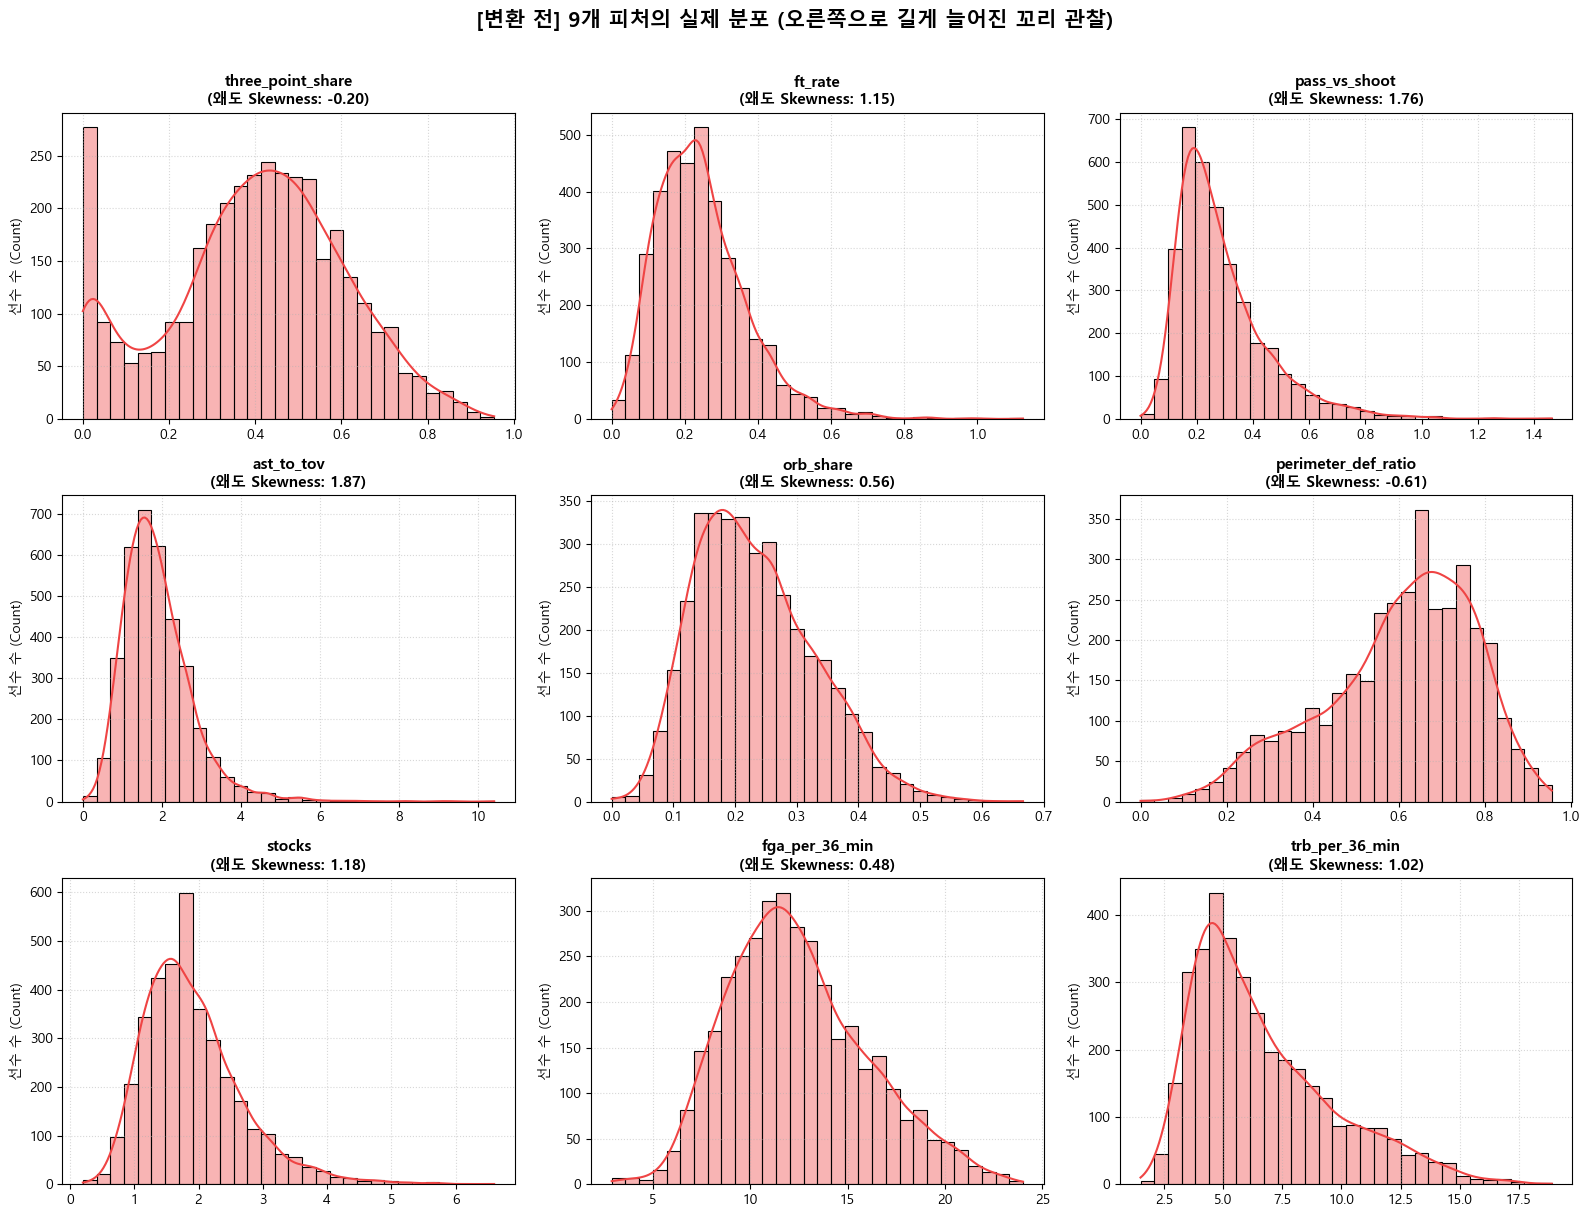

In [135]:
# 4. [EDA / 문제 제기] 9개 군집화 피처의 변환 전(Raw) 실제 분포 시각화
# ==============================================================================
# [발표 포인트 1: 문제 제기]
# 9개 피처 각각의 실제 히스토그램과 밀도 곡선(KDE)을 3x3 그리드로 출력합니다.
# 그래프를 보면 대부분의 데이터가 좌측에 몰려 있고, 오른쪽으로 꼬리가 길게 늘어져 있는(Right-Skewed)
# 비대칭 편향 현상을 눈으로 직접 확인할 수 있습니다.
# ==============================================================================
from scipy.stats import skew

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(cluster_features):
    sk_val = skew(df[col].dropna())
    sns.histplot(df[col], kde=True, color='#ef4444', alpha=0.4, ax=axes[idx], bins=30)
    axes[idx].set_title(f'{col}\n(왜도 Skewness: {sk_val:.2f})', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('선수 수 (Count)')
    axes[idx].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('[변환 전] 9개 피처의 실제 분포 (오른쪽으로 길게 늘어진 꼬리 관찰)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

=== 선별 3개 피처 log1p 변환 전후 왜도 비교 ===
                 변환 전 왜도   변환 후 왜도  왜도 감소율(%)
ast_to_tov      1.871156  0.349701       81.3
stocks          1.177049  0.297639       74.7
trb_per_36_min  1.022018  0.297308       70.9


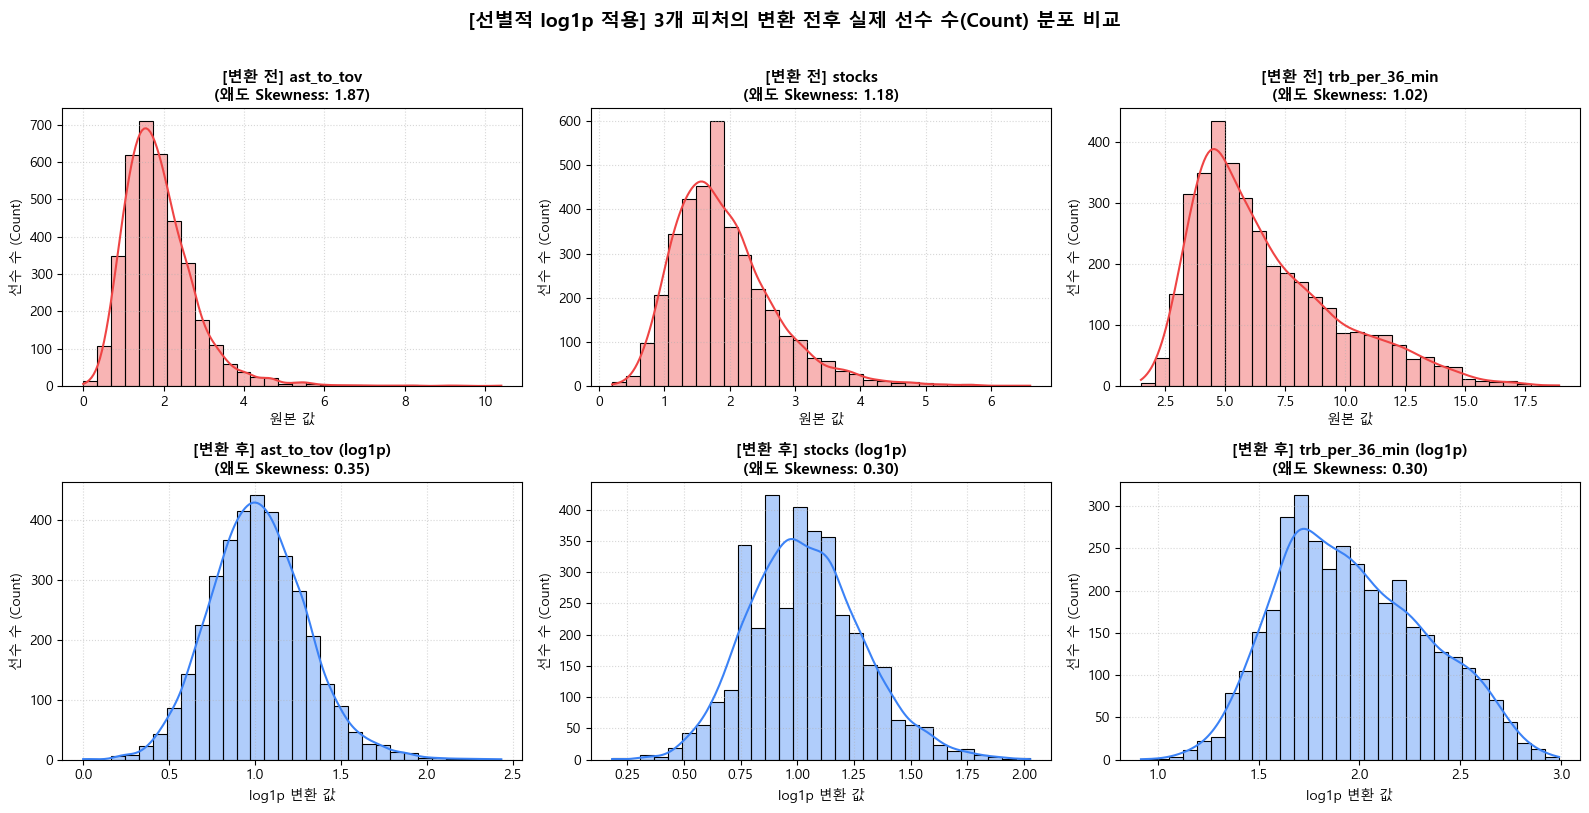


스케일링 완료: X_scaled shape=(3655, 9), X_scaled_log shape=(3655, 9)
최종 메인 학습 데이터셋(X_scaled_log) 생성 완료!


In [136]:
# 5. [피처 정규화 / 해결] 강한 왜도 3개 피처 선별적 log1p 변환, 효과 시각화 및 StandardScaler 적용
# ==============================================================================
# [선별적 로그 변환 전략]
# 1) pass_vs_shoot 등 비율 지표(0~1)는 수치 범위가 좁아 로그 변환의 실익이 없고 고유 거리를 보존해야 함
# 2) 우측 꼬리가 길고 극단치가 튀는 3개 피처(ast_to_tov, stocks, trb_per_36_min)만 선별적으로 np.log1p 적용
# 3) 상단(변환 전) vs 하단(변환 후)으로 실제 '선수 수(Count)' 기준 히스토그램을 비교 시각화
# 4) 정돈된 9개 피처를 대상으로 K-Means 학습을 위한 StandardScaler 완료
# ==============================================================================
from scipy.stats import skew

# (1) 선별 3개 피처 정의 및 log1p 변환 데이터프레임 생성
log_target_features = ['ast_to_tov', 'stocks', 'trb_per_36_min']

df_transformed = df[cluster_features].copy()
for col in log_target_features:
    df_transformed[col] = np.log1p(df_transformed[col])

# (2) 선별 3개 피처 변환 전후 왜도 비교표
skew_compare_df = pd.DataFrame({
    '변환 전 왜도': [skew(df[col].dropna()) for col in log_target_features],
    '변환 후 왜도': [skew(df_transformed[col].dropna()) for col in log_target_features]
}, index=log_target_features)
skew_compare_df['왜도 감소율(%)'] = ((skew_compare_df['변환 전 왜도'] - skew_compare_df['변환 후 왜도']) / skew_compare_df['변환 전 왜도'] * 100).round(1)

print('=== 선별 3개 피처 log1p 변환 전후 왜도 비교 ===')
print(skew_compare_df)

# (3) 시각화: 선별 3개 피처의 변환 전(상단) vs 변환 후(하단) 실제 '선수 수(Count)' 히스토그램 비교
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for idx, col in enumerate(log_target_features):
    before_sk = skew_compare_df.loc[col, '변환 전 왜도']
    after_sk = skew_compare_df.loc[col, '변환 후 왜도']
    
    # 1) 상단 행: 변환 전 (Raw) 히스토그램 (선수 수 기준)
    sns.histplot(df[col], color='#ef4444', kde=True, alpha=0.4, bins=30, ax=axes[0, idx])
    axes[0, idx].set_title(f'[변환 전] {col}\n(왜도 Skewness: {before_sk:.2f})', fontsize=11, fontweight='bold')
    axes[0, idx].set_xlabel('원본 값')
    axes[0, idx].set_ylabel('선수 수 (Count)')
    axes[0, idx].grid(True, linestyle=':', alpha=0.5)
    
    # 2) 하단 행: 변환 후 (log1p) 히스토그램 (선수 수 기준)
    sns.histplot(df_transformed[col], color='#3b82f6', kde=True, alpha=0.4, bins=30, ax=axes[1, idx])
    axes[1, idx].set_title(f'[변환 후] {col} (log1p)\n(왜도 Skewness: {after_sk:.2f})', fontsize=11, fontweight='bold')
    axes[1, idx].set_xlabel('log1p 변환 값')
    axes[1, idx].set_ylabel('선수 수 (Count)')
    axes[1, idx].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('[선별적 log1p 적용] 3개 피처의 변환 전후 실제 선수 수(Count) 분포 비교', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# (4) K-Means 모델링을 위한 표준화(StandardScaler) 적용
scaler = StandardScaler()

# 1) 원본 기반 스케일링 데이터셋 (비교 대조군)
X_scaled = scaler.fit_transform(df[cluster_features])

# 2) 선별 log1p 적용 후 스케일링 데이터셋 (최종 메인 학습용)
X_scaled_log = scaler.fit_transform(df_transformed)

print(f'\n스케일링 완료: X_scaled shape={X_scaled.shape}, X_scaled_log shape={X_scaled_log.shape}')
print('최종 메인 학습 데이터셋(X_scaled_log) 생성 완료!')

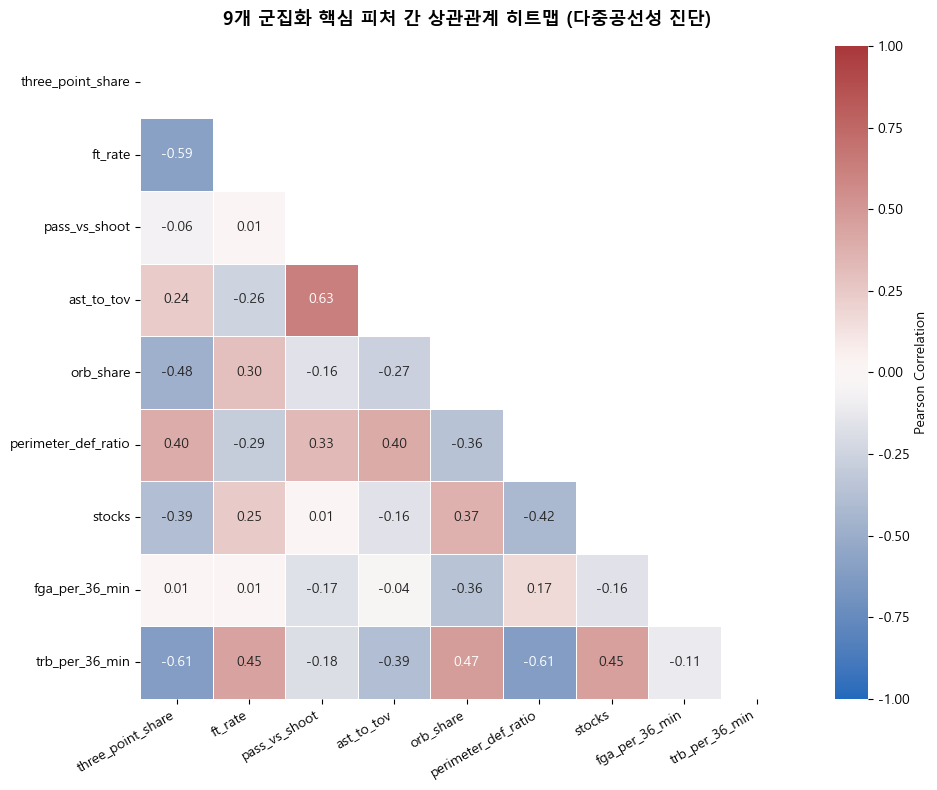

      [피처 간 다중공선성(중복 정보) 진단 결과]   
✅ 절대값 0.8 이상의 심각한 중복(다중공선성) 피처가 없습니다!
   -> 9개 피처가 특정 영역에 쏠리지 않고, 각자 독립적인 전술 정보를 고르게 반영하고 있습니다.


In [137]:
# 5-1. [피처 검증 / 상관관계 분석] 9개 군집화 핵심 피처 간 상관계수 히트맵 및 다중공선성 진단
# K-Means는 거리 기반 알고리즘이므로, 두 피처 간 상관관계가 너무 높으면(다중공선성) 특정 축에 가중치가 왜곡됩니다.
# 9개 피처가 서로 독립적이고 고유한 플레이스타일 정보를 담고 있는지 피어슨 상관계수로 검증합니다.

plt.figure(figsize=(10, 8))

# 9개 피처 간 상관계수 행렬 계산
corr_matrix = df[cluster_features].corr()

# 마스크 설정 (대각선 위쪽은 중복이므로 가리기)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 히트맵 시각화
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="vlag", 
            center=0, vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={'label': 'Pearson Correlation'})

plt.title("9개 군집화 핵심 피처 간 상관관계 히트맵 (다중공선성 진단)", fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 다중공선성(절대값 >= 0.8) 위험 쌍 자동 탐색
high_corr = []
for i in range(len(cluster_features)):
    for j in range(i + 1, len(cluster_features)):
        col1 = cluster_features[i]
        col2 = cluster_features[j]
        val = corr_matrix.loc[col1, col2]
        if abs(val) >= 0.8:
            high_corr.append((col1, col2, val))

print("=" * 60)
print("      [피처 간 다중공선성(중복 정보) 진단 결과]   ")
print("=" * 60)
if len(high_corr) == 0:
    print("✅ 절대값 0.8 이상의 심각한 중복(다중공선성) 피처가 없습니다!")
    print("   -> 9개 피처가 특정 영역에 쏠리지 않고, 각자 독립적인 전술 정보를 고르게 반영하고 있습니다.")
else:
    for c1, c2, val in high_corr:
        print(f"⚠️ 높은 상관관계 발견: {c1} & {c2} (r = {val:.2f})")

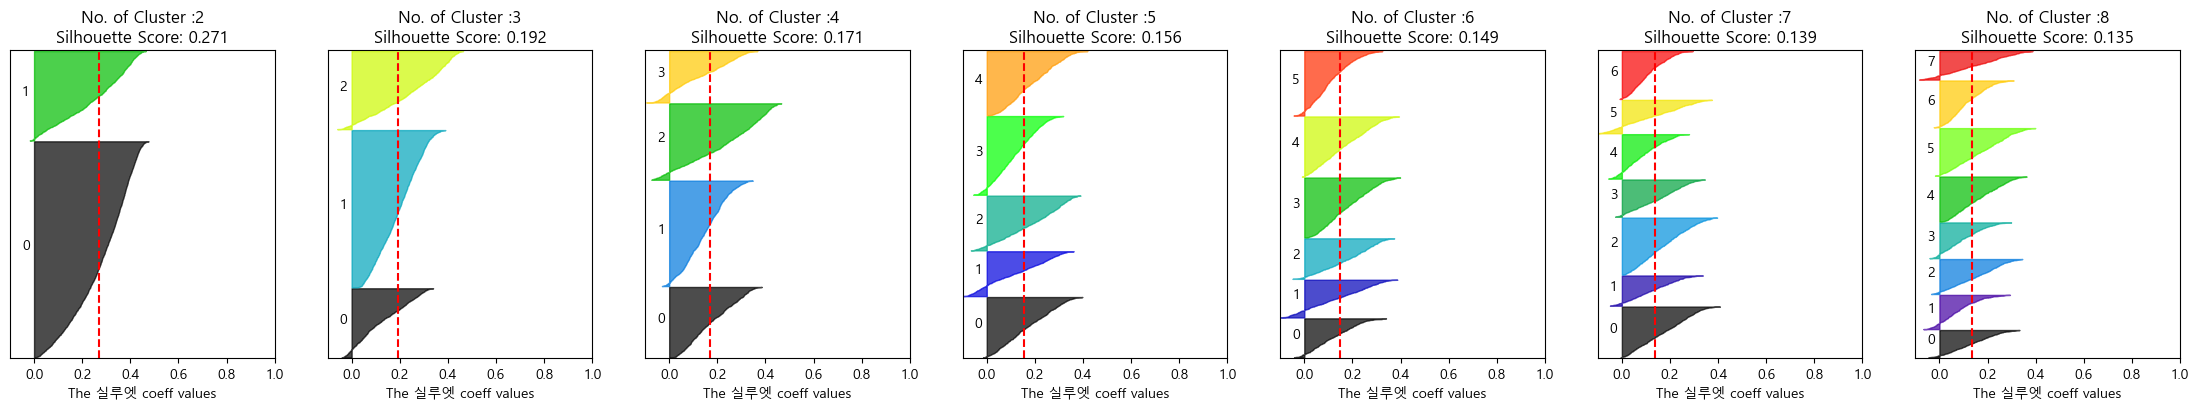

In [138]:
# 7. [군집 평가 2] 실루엣 다이어그램(Silhouette Diagram) 시각화 및 군집 균일도 검증
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.cm as cm

def visualize_silhouette(cluster_lists, X_features):
    import matplotlib.cm as cm

    n_cols = len(cluster_lists)
    fig, axs = plt.subplots(figsize = (4 * n_cols, 4), nrows=1, ncols=n_cols)

    for ind, n_cluster in enumerate(cluster_lists):
        clusterer = KMeans(n_clusters=n_cluster, max_iter=500, random_state=0, n_init=10)
        cluster_labels = clusterer.fit_predict(X_features)

        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)

        y_lower = 10
        axs[ind].set_title('No. of Cluster :' + str(n_cluster)+ '\n'+ 'Silhouette Score: '+str(round(sil_avg, 3)))
        axs[ind].set_xlabel('The 실루엣 coeff values')
        axs[ind].set_xlim([-0.1, 1])
        axs[ind].set_ylim([0, len(X_features) +(n_cluster + 1)* 10])
        axs[ind].set_yticks([])
        axs[ind].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])

        for i in range(n_cluster):
            ith_cluster_sil_values = sil_values[cluster_labels == i]
            ith_cluster_sil_values.sort()

            size_cluster_i = ith_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / n_cluster)
            axs[ind].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values, facecolor = color, edgecolor=color, alpha =0.7)
            axs[ind].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10
        axs[ind].axvline(x= sil_avg, color='red', linestyle = '--')

# K = 2, 3, 4, 5에 대해 실루엣 다이어그램 평가 실행
visualize_silhouette([2, 3, 4, 5, 6, 7, 8], X_scaled_log)

In [139]:
# 8. [모델링 & 다중 k 라벨링] K-Means (k=3, 4, 5) 학습 및 군집 레이블 부여
# 통계적 1차 후보인 k=3, 4, 5에 대해 정제된 9개 피처(X_scaled_log)로 KMeans 학습
#
# 💡 [중요 분석 가이드: 전통 포지션(pos) 교차표의 목적]
# - 아래 출력되는 '전통 포지션(pos)과의 교차표'는 k를 결정하기 위한 채점 기준이 아닙니다.
# - 만약 전통 포지션이 선수 스타일을 완벽히 대변한다면 군집화 머신러닝을 수행할 이유가 없습니다.
# - 교차표의 본래 목적:
#   1) [Sanity Check]: 센터와 가드가 무작위로 섞이지 않고 상식적인 경향성을 띠는지 확인
#   2) [포지션 파괴 증명]: SG와 SF가 하나의 윙 군집으로 묶이거나, 일부 빅맨이 외곽 슈터 군집으로 분류되는 등
#      '현대 농구의 포지션리스(Positionless) 트렌드'를 데이터로 입증하는 스토리텔링 장표입니다.
# - ※ 최종 k의 결정은 실루엣 다이어그램(7번 셀)과 11번 셀의 '실제 대체 선수 추천 정합성'으로 내립니다.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_candidates = [3, 4, 5]

print("=" * 60)
print("      [K-Means 다중 k(3, 4, 5) 학습 및 군집 분포 현황]   ")
print("=" * 60)

for k in k_candidates:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    col_name = f'cluster_k{k}'
    df[col_name] = kmeans.fit_predict(X_scaled_log)
    
    score = silhouette_score(X_scaled_log, df[col_name])
    counts = df[col_name].value_counts().sort_index().to_dict()
    
    print(f"\n▶ k = {k} (실루엣 점수: {score:.4f})")
    print(f"  - 군집별 선수 수 분포: {counts}")
    print(f"  - [참고용] 전통 포지션(pos) vs 군집 교차표 (포지션 파괴 트렌드 확인용):")
    display(pd.crosstab(df['pos'], df[col_name]))

      [K-Means 다중 k(3, 4, 5) 학습 및 군집 분포 현황]   

▶ k = 3 (실루엣 점수: 0.1920)
  - 군집별 선수 수 분포: {0: 828, 1: 941, 2: 1886}
  - [참고용] 전통 포지션(pos) vs 군집 교차표 (포지션 파괴 트렌드 확인용):


cluster_k3,0,1,2
pos,,,
C,27,613,70
PF,56,235,424
PG,476,6,191
SF,82,64,530
SG,187,23,671



▶ k = 4 (실루엣 점수: 0.1713)
  - 군집별 선수 수 분포: {0: 850, 1: 616, 2: 921, 3: 1268}
  - [참고용] 전통 포지션(pos) vs 군집 교차표 (포지션 파괴 트렌드 확인용):


cluster_k4,0,1,2,3
pos,,,,
C,31,19,614,46
PF,144,31,220,320
PG,230,380,5,58
SF,161,57,61,397
SG,284,129,21,447



▶ k = 5 (실루엣 점수: 0.1562)
  - 군집별 선수 수 분포: {0: 774, 1: 661, 2: 728, 3: 542, 4: 950}
  - [참고용] 전통 포지션(pos) vs 군집 교차표 (포지션 파괴 트렌드 확인용):


cluster_k5,0,1,2,3,4
pos,,,,,
C,5,522,16,18,149
PF,112,115,111,27,350
PG,89,2,224,341,17
SF,202,18,130,51,275
SG,366,4,247,105,159


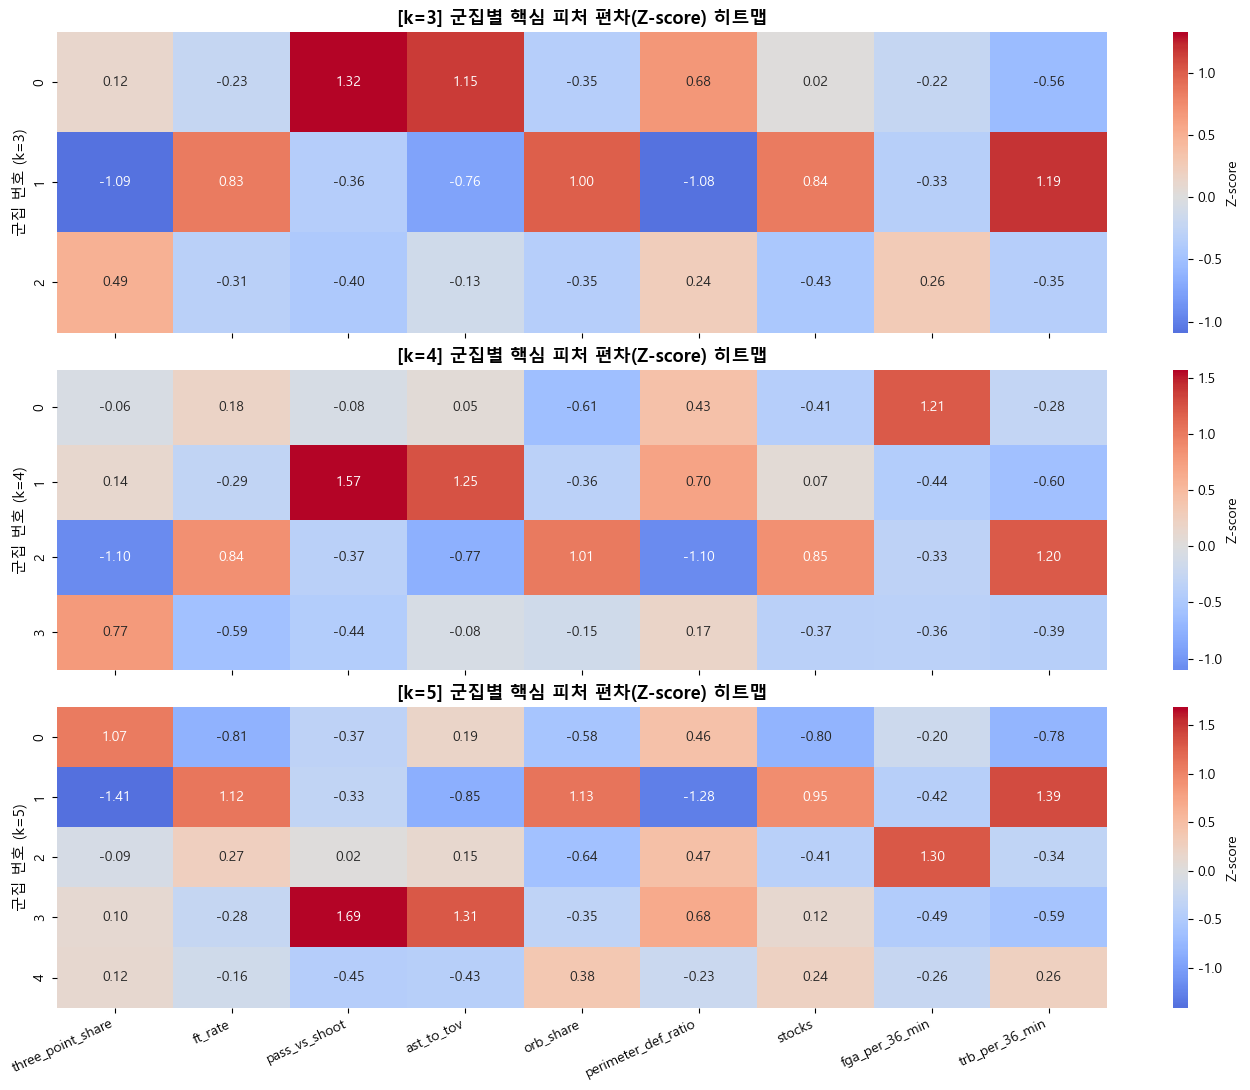

      [k=3, 4, 5 각 군집별 인구수 및 대표 주전 선수 (샘플 5명)]   

==================== ★ [k = 3] 군집별 특성 및 대표 선수 ====================
▶ 군집 0 (선수 828명, 22.7%):
   - 대표 선수 (fga_per_36_min 상위): Ty Jerome, Shai Gilgeous-Alexander, Trae Young, Ja Morant, LeBron James
▶ 군집 1 (선수 941명, 25.7%):
   - 대표 선수 (fga_per_36_min 상위): Joel Embiid, Giannis Antetokounmpo, Zion Williamson, Victor Wembanyama, Shai Gilgeous-Alexander
▶ 군집 2 (선수 1886명, 51.6%):
   - 대표 선수 (fga_per_36_min 상위): LaMelo Ball, James Harden, Duane Washington Jr., Bradley Beal, Shai Gilgeous-Alexander

==================== ★ [k = 4] 군집별 특성 및 대표 선수 ====================
▶ 군집 0 (선수 850명, 23.3%):
   - 대표 선수 (fga_per_36_min 상위): James Harden, LaMelo Ball, Duane Washington Jr., Bradley Beal, Giannis Antetokounmpo
▶ 군집 1 (선수 616명, 16.9%):
   - 대표 선수 (fga_per_36_min 상위): Trae Young, Markelle Fultz, Tyrese Haliburton, T.J. McConnell, J.J. Barea
▶ 군집 2 (선수 921명, 25.2%):
   - 대표 선수 (fga_per_36_min 상위): Joel Embiid, Zion Williamson, Victor Wembanyama, Giannis 

In [140]:
# 9. [군집 심층 프로파일링] k=3, 4, 5별 군집 특성 비교 및 도메인 롤(Role) 정체성 해부
# 군집 크기의 인위적 균일도보다 "군집별 전술적 특성과 대표 선수가 농구적으로 명확히 납득되는가"를 기준으로 최적 k를 판별합니다.

fig, axs = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

df_scaled_profile = pd.DataFrame(X_scaled_log, columns=cluster_features)

for idx, k in enumerate([3, 4, 5]):
    col = f'cluster_k{k}'
    df_scaled_profile[col] = df[col].values
    z_mean = df_scaled_profile.groupby(col)[cluster_features].mean()
    
    sns.heatmap(z_mean, annot=True, fmt=".2f", cmap="coolwarm", center=0, 
                cbar_kws={'label': 'Z-score'}, ax=axs[idx])
    axs[idx].set_title(f"[k={k}] 군집별 핵심 피처 편차(Z-score) 히트맵", fontsize=13, fontweight='bold')
    axs[idx].set_ylabel(f"군집 번호 (k={k})", fontsize=11)

plt.xticks(rotation=25, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 각 k별 군집의 대표 선수 (팀 내 볼륨 상위 주전급 샘플 5명) 및 인구수 출력
# -------------------------------------------------------------
print("=" * 80)
print("      [k=3, 4, 5 각 군집별 인구수 및 대표 주전 선수 (샘플 5명)]   ")
print("=" * 80)

for k in [3, 4, 5]:
    col = f'cluster_k{k}'
    print(f"\n==================== ★ [k = {k}] 군집별 특성 및 대표 선수 ====================")
    for c in sorted(df[col].unique()):
        c_players_all = df[df[col] == c]
        total_count = len(c_players_all)
        pct = total_count / len(df) * 100
        
        # 대표 선수: 야투 시도(fga_per_36_min) 상위 5명 (팀 내 공격 비중이 높은 핵심 주전급)
        # 만약 mp 컬럼이 있다면 mp 기준, 없으면 fga_per_36_min 기준 정렬
        sort_col = 'mp' if 'mp' in c_players_all.columns else 'fga_per_36_min'
        sample_top = c_players_all.sort_values(sort_col, ascending=False)['player'].unique()[:5]
        sample_str = ", ".join(sample_top) if len(sample_top) > 0 else "샘플 부족"
        
        print(f"▶ 군집 {c} (선수 {total_count}명, {pct:.1f}%):")
        print(f"   - 대표 선수 ({sort_col} 상위): {sample_str}")

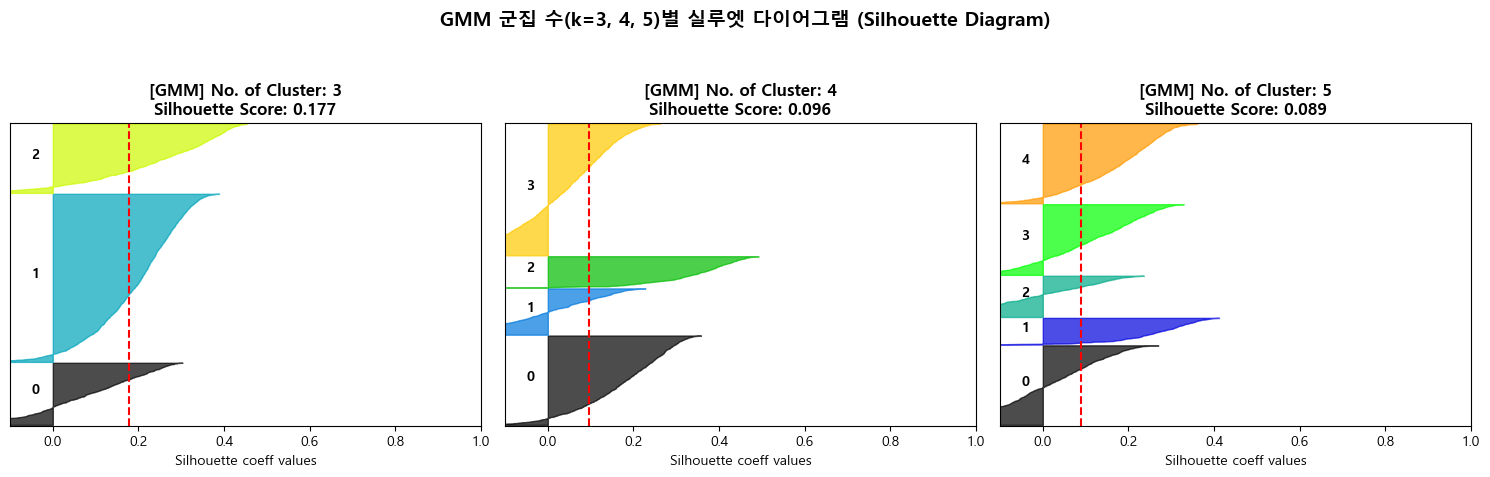

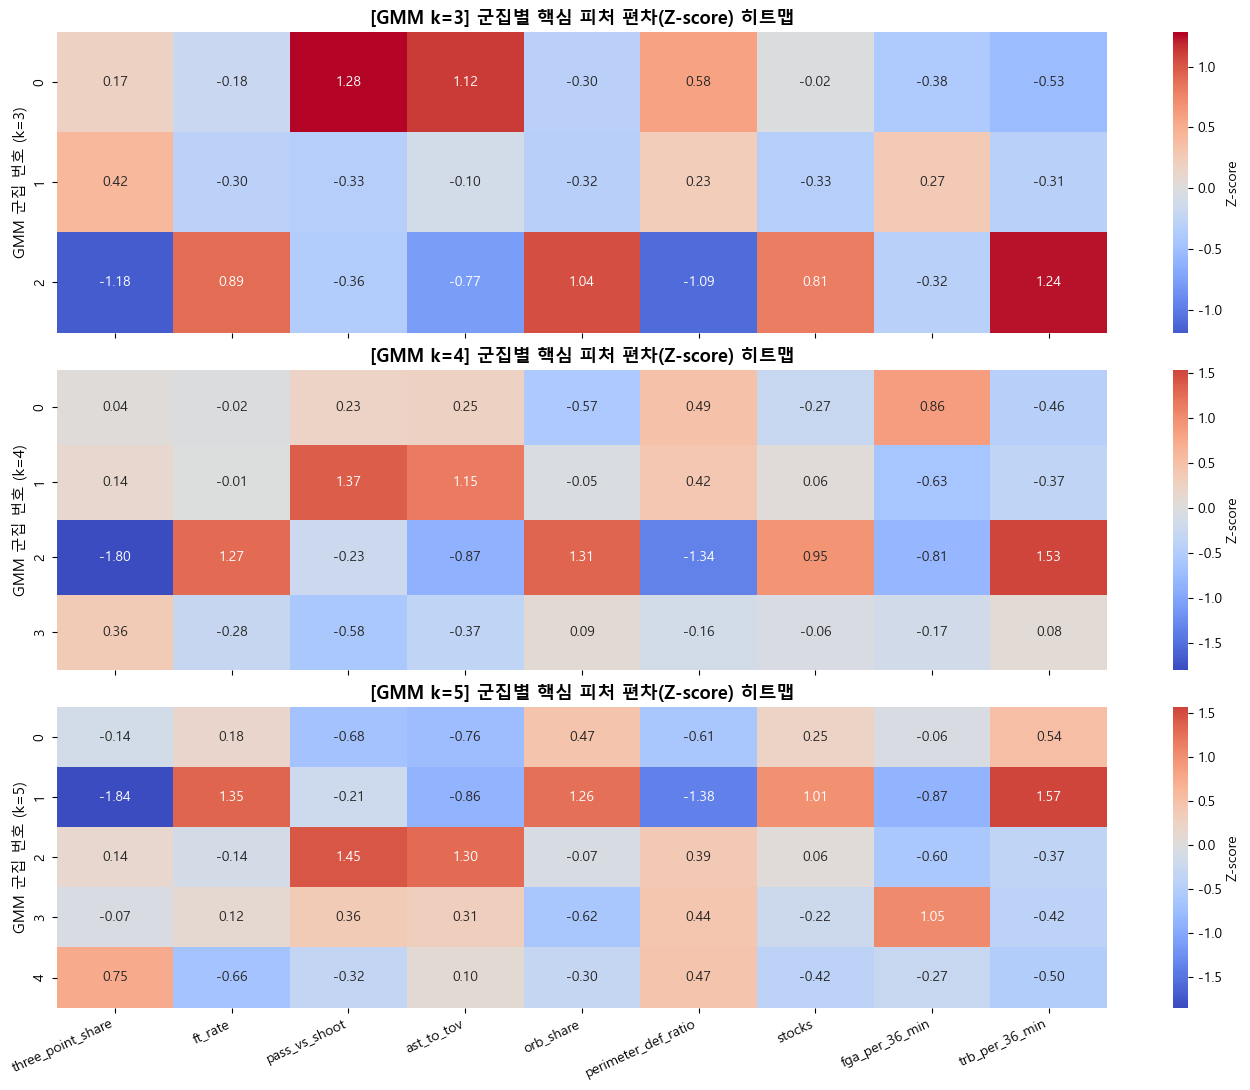

      [GMM k=3, 4, 5 각 군집별 인구수 및 대표 주전 선수 (샘플 5명)]   

==================== ★ [GMM k = 3] 군집별 특성 및 대표 선수 ====================
▶ 군집 0 (선수 759명, 20.8%):
   - 대표 선수: Trae Young, Russell Westbrook, Walt Lemon Jr., J.J. Barea, John Wall
▶ 군집 1 (선수 2052명, 56.1%):
   - 대표 선수: James Harden, LaMelo Ball, Duane Washington Jr., Bradley Beal, Luka Dončić
▶ 군집 2 (선수 844명, 23.1%):
   - 대표 선수: Joel Embiid, Giannis Antetokounmpo, James Harden, Nikola Vučević, Victor Wembanyama

==================== ★ [GMM k = 4] 군집별 특성 및 대표 선수 ====================
▶ 군집 0 (선수 1094명, 29.9%):
   - 대표 선수: James Harden, LaMelo Ball, Joel Embiid, Duane Washington Jr., Giannis Antetokounmpo
▶ 군집 1 (선수 567명, 15.5%):
   - 대표 선수: Walt Lemon Jr., Markelle Fultz, Adam Flagler, Tyrese Haliburton, T.J. McConnell
▶ 군집 2 (선수 384명, 10.5%):
   - 대표 선수: Johnathan Motley, Deandre Ayton, Paul Reed, Jusuf Nurkić, Andre Drummond
▶ 군집 3 (선수 1610명, 44.0%):
   - 대표 선수: Victor Wembanyama, Anthony Davis, Michael Beasley, Jaren Jackson Jr., Nikol

In [141]:
# 10. [알고리즘 비교 1] GMM(가우시안 혼합 모델) 심층 분석: 실루엣 다이어그램 & 군집 특성 히트맵
# K-Means와 동일한 기준으로 GMM(k=3, 4, 5)의 실루엣 다이어그램 형상 및 도메인 스탯 편차(Z-score)를 시각적으로 대조합니다.

import matplotlib.cm as cm
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_samples, silhouette_score

k_list = [3, 4, 5]

# -------------------------------------------------------------
# 1. GMM 모델 학습 및 실루엣 다이어그램 시각화 (k=3, 4, 5)
# -------------------------------------------------------------
n_cols = len(k_list)
fig, axs = plt.subplots(figsize=(5 * n_cols, 4.5), nrows=1, ncols=n_cols)

for ind, n_cluster in enumerate(k_list):
    gmm = GaussianMixture(n_components=n_cluster, random_state=42, n_init=3)
    col_name = f'cluster_gmm_k{n_cluster}'
    cluster_labels = gmm.fit_predict(X_scaled_log)
    df[col_name] = cluster_labels

    sil_avg = silhouette_score(X_scaled_log, cluster_labels)
    sil_values = silhouette_samples(X_scaled_log, cluster_labels)

    y_lower = 10
    axs[ind].set_title(f'[GMM] No. of Cluster: {n_cluster}\nSilhouette Score: {sil_avg:.3f}', fontsize=12, fontweight='bold')
    axs[ind].set_xlabel('Silhouette coeff values')
    axs[ind].set_xlim([-0.1, 1])
    axs[ind].set_ylim([0, len(X_scaled_log) + (n_cluster + 1) * 10])
    axs[ind].set_yticks([])
    axs[ind].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])

    for i in range(n_cluster):
        ith_cluster_sil_values = sil_values[cluster_labels == i]
        ith_cluster_sil_values.sort()

        size_cluster_i = ith_cluster_sil_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_cluster)
        axs[ind].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values, facecolor=color, edgecolor=color, alpha=0.7)
        axs[ind].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=10, fontweight='bold')
        y_lower = y_upper + 10

    axs[ind].axvline(x=sil_avg, color='red', linestyle='--')

plt.suptitle("GMM 군집 수(k=3, 4, 5)별 실루엣 다이어그램 (Silhouette Diagram)", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 2. GMM 군집별 피처 편차(Z-score) 히트맵 시각화 (k=3, 4, 5)
# -------------------------------------------------------------
fig, axs = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
df_scaled_profile = pd.DataFrame(X_scaled_log, columns=cluster_features)

for idx, k in enumerate(k_list):
    col = f'cluster_gmm_k{k}'
    df_scaled_profile[col] = df[col].values
    z_mean = df_scaled_profile.groupby(col)[cluster_features].mean()
    
    sns.heatmap(z_mean, annot=True, fmt=".2f", cmap="coolwarm", center=0, 
                cbar_kws={'label': 'Z-score'}, ax=axs[idx])
    axs[idx].set_title(f"[GMM k={k}] 군집별 핵심 피처 편차(Z-score) 히트맵", fontsize=13, fontweight='bold')
    axs[idx].set_ylabel(f"GMM 군집 번호 (k={k})", fontsize=11)

plt.xticks(rotation=25, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 3. GMM 군집별 대표 선수 (fga_per_36_min 상위 5명) 및 인구수 출력
# -------------------------------------------------------------
print("=" * 80)
print("      [GMM k=3, 4, 5 각 군집별 인구수 및 대표 주전 선수 (샘플 5명)]   ")
print("=" * 80)

for k in k_list:
    col = f'cluster_gmm_k{k}'
    print(f"\n==================== ★ [GMM k = {k}] 군집별 특성 및 대표 선수 ====================")
    for c in sorted(df[col].unique()):
        c_players_all = df[df[col] == c]
        total_count = len(c_players_all)
        pct = total_count / len(df) * 100
        
        sample_top = c_players_all.sort_values('fga_per_36_min', ascending=False)['player'].unique()[:5]
        sample_str = ", ".join(sample_top) if len(sample_top) > 0 else "샘플 부족"
        
        print(f"▶ 군집 {c} (선수 {total_count}명, {pct:.1f}%):")
        print(f"   - 대표 선수: {sample_str}")

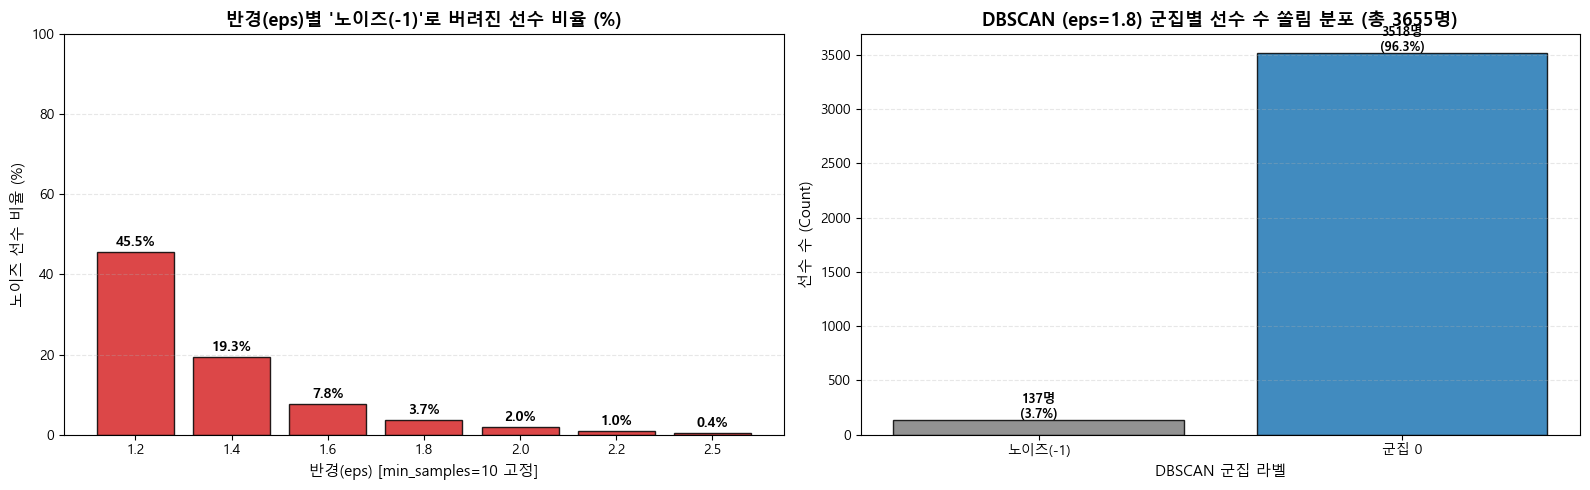

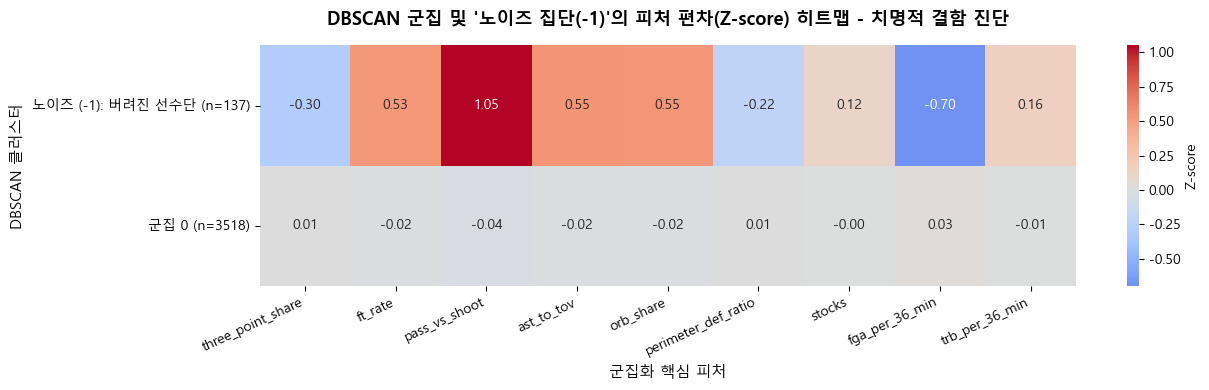

      [DBSCAN 한계 결론: 밀도 부족으로 '노이즈(-1)'로 배제된 대표 스타 선수들]   
⚠️ 독보적 에이스라 밀도가 낮다는 이유로 버려진 대표 선수 (야투 시도 상위 10명):
   👉 Victor Wembanyama, Markus Howard, Zion Williamson, Jordan Nwora, Patrick Baldwin Jr., Luka Garza, Dirk Nowitzki, Chris Boucher, Paul Reed, Jaylen Nowell


In [142]:
# 11. [알고리즘 비교 2] DBSCAN(밀도 기반 군집화) 심층 시각화 및 한계점 진단
# (1) 반경(eps)별 노이즈 발생 비율, (2) 군집별 극단적 인구 쏠림, (3) 노이즈 집단을 포함한 피처 편차(Z-score) 히트맵 시각화

from sklearn.cluster import DBSCAN

# -------------------------------------------------------------
# 1. 반경(eps)에 따른 노이즈(-1) 발생 비율 및 군집 크기 시각화
# -------------------------------------------------------------
eps_values = [1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5]
noise_ratios = []
cluster_counts = []

for e in eps_values:
    db = DBSCAN(eps=e, min_samples=10)
    lbls = db.fit_predict(X_scaled_log)
    n_c = len(set(lbls)) - (1 if -1 in lbls else 0)
    n_n = list(lbls).count(-1)
    noise_ratios.append(n_n / len(lbls) * 100)
    cluster_counts.append(n_c)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 차트 1-1: eps별 노이즈 비율
bars = axes[0].bar([str(e) for e in eps_values], noise_ratios, color='#d62728', alpha=0.85, edgecolor='black')
axes[0].set_title("반경(eps)별 '노이즈(-1)'로 버려진 선수 비율 (%)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("반경(eps) [min_samples=10 고정]", fontsize=11)
axes[0].set_ylabel("노이즈 선수 비율 (%)", fontsize=11)
axes[0].set_ylim(0, 100)
axes[0].grid(True, linestyle='--', alpha=0.3, axis='y')
for bar, r in zip(bars, noise_ratios):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f'{r:.1f}%', ha='center', fontsize=10, fontweight='bold')

# 차트 1-2: 대표 파라미터 (eps=1.8, min_samples=10) 군집별 인구 쏠림 분포
db_rep = DBSCAN(eps=1.8, min_samples=10)
df['cluster_dbscan'] = db_rep.fit_predict(X_scaled_log)
dist = df['cluster_dbscan'].value_counts().sort_index()

colors_dist = ['#7f7f7f' if idx == -1 else '#1f77b4' for idx in dist.index]
labels_dist = [f"노이즈({idx})" if idx == -1 else f"군집 {idx}" for idx in dist.index]

axes[1].bar(labels_dist, dist.values, color=colors_dist, alpha=0.85, edgecolor='black')
axes[1].set_title(f"DBSCAN (eps=1.8) 군집별 선수 수 쏠림 분포 (총 {len(df)}명)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("DBSCAN 군집 라벨", fontsize=11)
axes[1].set_ylabel("선수 수 (Count)", fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.3, axis='y')
for i, v in enumerate(dist.values):
    axes[1].text(i, v + 20, f'{v}명\n({v/len(df)*100:.1f}%)', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 2. DBSCAN 군집 및 '노이즈 집단(-1)'의 핵심 피처 편차(Z-score) 히트맵
# -------------------------------------------------------------
df_scaled_db = pd.DataFrame(X_scaled_log, columns=cluster_features)
df_scaled_db['cluster_dbscan'] = df['cluster_dbscan'].values
z_mean_db = df_scaled_db.groupby('cluster_dbscan')[cluster_features].mean()

# y축 인덱스 이름 레이블링 (-1: 노이즈로 버려진 선수들)
z_mean_db.index = [f"노이즈 (-1): 버려진 선수단 (n={dist[idx]})" if idx == -1 else f"군집 {idx} (n={dist[idx]})" for idx in z_mean_db.index]

plt.figure(figsize=(13, max(4, len(z_mean_db) * 1.2)))
sns.heatmap(z_mean_db, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={'label': 'Z-score'})
plt.title("DBSCAN 군집 및 '노이즈 집단(-1)'의 피처 편차(Z-score) 히트맵 - 치명적 결함 진단", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("군집화 핵심 피처", fontsize=11)
plt.ylabel("DBSCAN 클러스터", fontsize=11)
plt.xticks(rotation=25, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 3. 노이즈(-1)로 버려진 대표 주전 선수 확인
# -------------------------------------------------------------
print("=" * 75)
print("      [DBSCAN 한계 결론: 밀도 부족으로 '노이즈(-1)'로 배제된 대표 스타 선수들]   ")
print("=" * 75)
noise_sample = df[df['cluster_dbscan'] == -1].sort_values('fga_per_36_min', ascending=False)['player'].unique()[:10]
print(f"⚠️ 독보적 에이스라 밀도가 낮다는 이유로 버려진 대표 선수 (야투 시도 상위 10명):")
print(f"   👉 {', '.join(noise_sample)}")

      [Mean Shift 분위수(quantile)별 대역폭 탐색 및 군집 형성 현황]   


,분위수 (quantile),추정 대역폭 (bandwidth),자동 결정된 군집 수,실루엣 점수
0,0.20,2.990,5,0.125
1,0.25,3.157,3,0.253
2,0.30,3.310,2,0.501
3,0.35,3.455,2,0.501


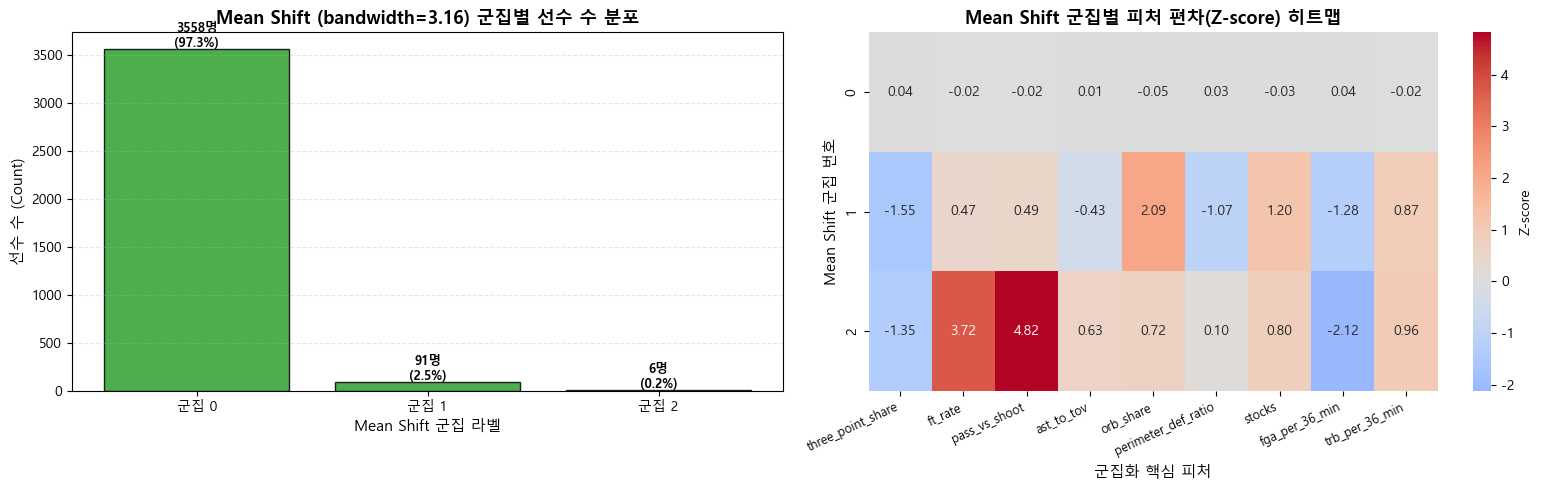

      [Mean Shift 각 군집별 대표 주전 선수 (샘플 5명)]   
▶ 군집 0 (3558명, 97.3%): LaMelo Ball, James Harden, Joel Embiid, Duane Washington Jr., Giannis Antetokounmpo
▶ 군집 1 (91명, 2.5%): Paul Reed, Nate Williams, Robin Lopez, Nikola Topić, Joan Beringer
▶ 군집 2 (6명, 0.2%): Draymond Green, Dwight Powell, Mason Plumlee


In [143]:
# 12. [알고리즘 비교 3] 평균 이동 (Mean Shift) 군집화 및 대역폭(Bandwidth) 민감도 분석
# 군집 수를 사전에 지정하지 않고, 데이터의 밀도 봉우리(KDE 피크)를 찾아 이동하는 Mean Shift 알고리즘을 평가합니다.
# 교재 ch07_3에서 다룬 estimate_bandwidth 함수로 최적 대역폭을 탐색하고, 고차원 데이터에서의 적합성을 진단합니다.

from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.metrics import silhouette_score

# -------------------------------------------------------------
# 1. 분위수(quantile)에 따른 최적 대역폭(bandwidth) 탐색 및 군집 형성 비교
# -------------------------------------------------------------
quantiles = [0.2, 0.25, 0.3, 0.35]
ms_results = []

print("=" * 75)
print("      [Mean Shift 분위수(quantile)별 대역폭 탐색 및 군집 형성 현황]   ")
print("=" * 75)

for q in quantiles:
    # 대역폭 자동 추정 (계산 속도를 위해 n_samples 샘플링 활용)
    bw = estimate_bandwidth(X_scaled_log, quantile=q, n_samples=500, random_state=42)
    ms = MeanShift(bandwidth=bw)
    labels = ms.fit_predict(X_scaled_log)
    
    n_c = len(set(labels))
    counts = pd.Series(labels).value_counts().to_dict()
    
    if n_c >= 2:
        sil = silhouette_score(X_scaled_log, labels)
    else:
        sil = np.nan
        
    ms_results.append({
        '분위수 (quantile)': q,
        '추정 대역폭 (bandwidth)': round(bw, 3),
        '자동 결정된 군집 수': n_c,
        '실루엣 점수': f"{sil:.3f}" if not np.isnan(sil) else "계산불가",
        '군집별 인구수 분포': counts
    })

df_ms = pd.DataFrame(ms_results)
display(df_ms[['분위수 (quantile)', '추정 대역폭 (bandwidth)', '자동 결정된 군집 수', '실루엣 점수']])

# -------------------------------------------------------------
# 2. 대표 대역폭 모델 상세 시각화: 군집 쏠림 및 피처 편차(Z-score) 히트맵
# -------------------------------------------------------------
# 가장 유의미한 군집 수를 형성한 대역폭 선택 (quantile=0.25 기준)
best_bw = df_ms.loc[1, '추정 대역폭 (bandwidth)']
ms_best = MeanShift(bandwidth=best_bw)
df['cluster_meanshift'] = ms_best.fit_predict(X_scaled_log)
ms_dist = df['cluster_meanshift'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 차트 1: 군집 크기 쏠림 분포
axes[0].bar([f"군집 {i}" for i in ms_dist.index], ms_dist.values, color='#2ca02c', alpha=0.85, edgecolor='black')
axes[0].set_title(f"Mean Shift (bandwidth={best_bw:.2f}) 군집별 선수 수 분포", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Mean Shift 군집 라벨", fontsize=11)
axes[0].set_ylabel("선수 수 (Count)", fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.3, axis='y')
for i, v in enumerate(ms_dist.values):
    axes[0].text(i, v + 25, f'{v}명\n({v/len(df)*100:.1f}%)', ha='center', fontsize=9, fontweight='bold')

# 차트 2: 군집별 피처 편차(Z-score) 히트맵
df_scaled_ms = pd.DataFrame(X_scaled_log, columns=cluster_features)
df_scaled_ms['cluster_meanshift'] = df['cluster_meanshift'].values
z_mean_ms = df_scaled_ms.groupby('cluster_meanshift')[cluster_features].mean()

sns.heatmap(z_mean_ms, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={'label': 'Z-score'}, ax=axes[1])
axes[1].set_title("Mean Shift 군집별 피처 편차(Z-score) 히트맵", fontsize=13, fontweight='bold')
axes[1].set_xlabel("군집화 핵심 피처", fontsize=11)
axes[1].set_ylabel("Mean Shift 군집 번호", fontsize=11)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=25, ha='right', fontsize=9)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 3. 각 군집별 대표 주전 선수 확인
# -------------------------------------------------------------
print("=" * 75)
print("      [Mean Shift 각 군집별 대표 주전 선수 (샘플 5명)]   ")
print("=" * 75)
for c in sorted(df['cluster_meanshift'].unique()):
    c_players = df[df['cluster_meanshift'] == c]
    top_p = c_players.sort_values('fga_per_36_min', ascending=False)['player'].unique()[:5]
    print(f"▶ 군집 {c} ({len(c_players)}명, {len(c_players)/len(df)*100:.1f}%): {', '.join(top_p)}")

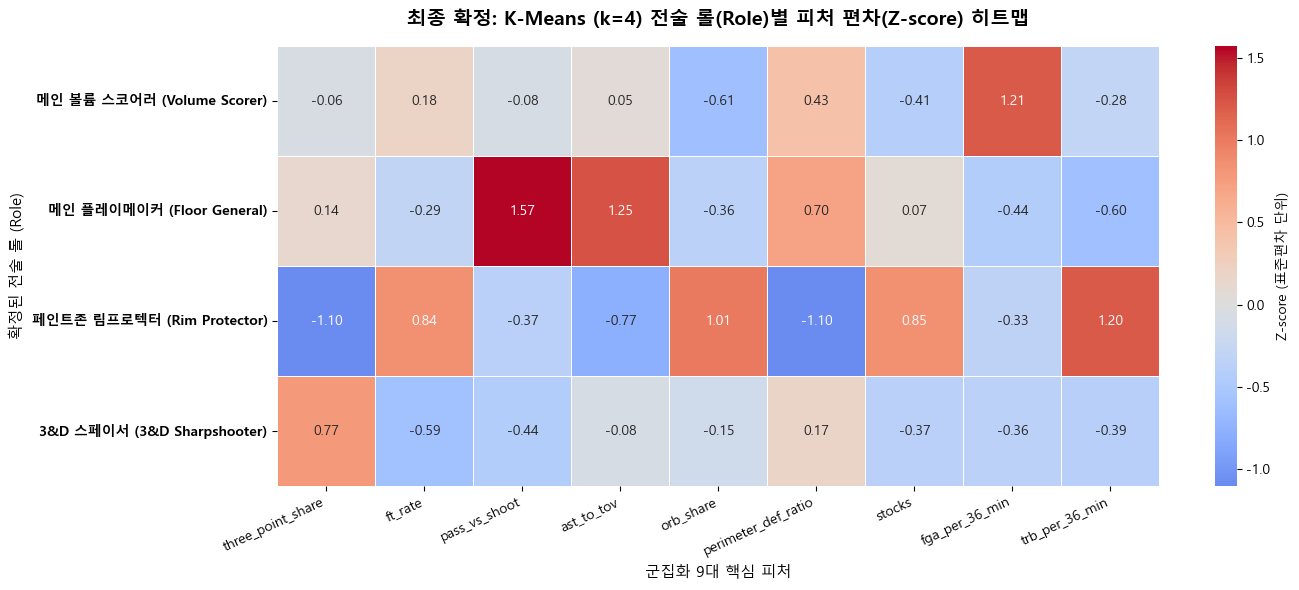

      [K-Means (k=4) 최종 4대 롤(Role) 선정 근거 및 대표 선수]   

▶ [0번 롤] 메인 볼륨 스코어러 (Volume Scorer) (총 850명, 23.3%)
   - 네이밍 근거: 야투 시도(fga_per_36_min)가 +1.21로 독보적 1위 -> 직접 슛을 던져 득점을 전담하는 1옵션 주포
   - 대표 주전 선수: James Harden, LaMelo Ball, Duane Washington Jr., Bradley Beal, Giannis Antetokounmpo

▶ [1번 롤] 메인 플레이메이커 (Floor General) (총 616명, 16.9%)
   - 네이밍 근거: 패스 성향(pass_vs_shoot: +1.57) 및 볼 안정성(ast_to_tov: +1.25) 압도적 1위 -> 경기 조율 사령관
   - 대표 주전 선수: Trae Young, Markelle Fultz, Tyrese Haliburton, T.J. McConnell, J.J. Barea

▶ [2번 롤] 페인트존 림프로텍터 (Rim Protector) (총 921명, 25.2%)
   - 네이밍 근거: 리바운드(trb: +1.20, orb: +1.01) 및 수비 활동량(stocks: +0.85) 압도적 1위 -> 골밑 페인트존 지배자
   - 대표 주전 선수: Joel Embiid, Zion Williamson, Victor Wembanyama, Giannis Antetokounmpo, Anthony Davis

▶ [3번 롤] 3&D 스페이서 (3&D Sharpshooter) (총 1268명, 34.7%)
   - 네이밍 근거: 3점슛 비중(three_point_share: +0.77) 독보적 1위 -> 외곽 공간을 벌려주는 전문 슈터 및 윙
   - 대표 주전 선수: Chris Clemons, Klay Thompson, Patrick Baldwin Jr., Adam Flagler, Malik Beasley


In [144]:
# 13. [최종 모델 확정] K-Means (k=4) 기반 4대 전술 롤(Role) 네이밍 및 피처별 도메인 해석
# 히트맵 상의 독보적인 피처 1등 스탯을 바탕으로 각 군집의 전술적 정체성을 정의하고 공식 롤(Role) 이름을 부여합니다.
#
# 💡 [9대 핵심 피처가 뜻하는 도메인 의미]
# 1. three_point_share   : 3PAr (전체 야투 중 3점슛 시도 비율) -> 외곽 공간 창출(스페이싱) 능력
# 2. ft_rate             : FTr (야투 시도 대비 자유투 획득 비율) -> 적극적 림 어택 및 파울 유도력
# 3. pass_vs_shoot       : AST / FGA (야투 대비 어시스트 비율) -> 개인 득점형 vs 패스 우선형 판단
# 4. ast_to_tov          : A/T Ratio (어시스트 대 턴오버 비율) -> 공을 다루는 안정성과 리딩 퀄리티
# 5. orb_share           : ORB / TRB (총 리바운드 중 공격 리바운드 비율) -> 골밑 적극적 보드 경합력
# 6. perimeter_def_ratio : STL / (STL + BLK) -> 외곽 앞선 수비수(1에 수렴) vs 골밑 림 보호자(0에 수렴)
# 7. stocks              : STL + BLK -> 36분당 종합 수비 활동량 및 기여도
# 8. fga_per_36_min      : 36분 환산 야투 시도량 -> 팀 내 1옵션 주포(공격 볼륨) 여부 판별
# 9. trb_per_36_min      : 36분 환산 총 리바운드 -> 선수의 신장/체격 기반 순수 골밑 장악력

# 1. 4대 전술 롤(Role) 공식 매핑
role_map = {
    0: '메인 볼륨 스코어러 (Volume Scorer)',
    1: '메인 플레이메이커 (Floor General)',
    2: '페인트존 림프로텍터 (Rim Protector)',
    3: '3&D 스페이서 (3&D Sharpshooter)'
}

df['final_cluster'] = df['cluster_k4']
df['final_role'] = df['final_cluster'].map(role_map)

# 2. 롤 네이밍이 반영된 최종 Z-score 히트맵 시각화
df_scaled_final = pd.DataFrame(X_scaled_log, columns=cluster_features)
df_scaled_final['final_role'] = df['final_role'].values
z_mean_final = df_scaled_final.groupby('final_role')[cluster_features].mean()

# 군집 순서 정렬 (0, 1, 2, 3 순서)
ordered_roles = [role_map[i] for i in range(4)]
z_mean_final = z_mean_final.reindex(ordered_roles)

plt.figure(figsize=(14, 6))
sns.heatmap(z_mean_final, annot=True, fmt=".2f", cmap="coolwarm", center=0, 
            cbar_kws={'label': 'Z-score (표준편차 단위)'}, linewidths=0.5)
plt.title("최종 확정: K-Means (k=4) 전술 롤(Role)별 피처 편차(Z-score) 히트맵", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("군집화 9대 핵심 피처", fontsize=11)
plt.ylabel("확정된 전술 롤 (Role)", fontsize=11)
plt.xticks(rotation=25, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. 각 롤별 네이밍 근거 및 대표 선수 명단 출력
print("=" * 80)
print("      [K-Means (k=4) 최종 4대 롤(Role) 선정 근거 및 대표 선수]   ")
print("=" * 80)

reasons = {
    0: "야투 시도(fga_per_36_min)가 +1.21로 독보적 1위 -> 직접 슛을 던져 득점을 전담하는 1옵션 주포",
    1: "패스 성향(pass_vs_shoot: +1.57) 및 볼 안정성(ast_to_tov: +1.25) 압도적 1위 -> 경기 조율 사령관",
    2: "리바운드(trb: +1.20, orb: +1.01) 및 수비 활동량(stocks: +0.85) 압도적 1위 -> 골밑 페인트존 지배자",
    3: "3점슛 비중(three_point_share: +0.77) 독보적 1위 -> 외곽 공간을 벌려주는 전문 슈터 및 윙"
}

for c_id, r_name in role_map.items():
    c_players = df[df['final_cluster'] == c_id]
    count = len(c_players)
    pct = count / len(df) * 100
    top_stars = c_players.sort_values('fga_per_36_min', ascending=False)['player'].unique()[:5]
    
    print(f"\n▶ [{c_id}번 롤] {r_name} (총 {count}명, {pct:.1f}%)")
    print(f"   - 네이밍 근거: {reasons[c_id]}")
    print(f"   - 대표 주전 선수: {', '.join(top_stars)}")

In [145]:
# 14. [피날레: 최종 추천 시스템] NBA 결장/이탈 자원 최적 대체 선수 추천 엔진 (recommend_substitute)
# 타겟 선수의 결장 발생 시, 동일한 전술 롤(final_role) 내에서 9대 핵심 스탯 기반 코사인 유사도(Cosine Similarity)가 가장 높은 대체 선수를 추천합니다.

from sklearn.metrics.pairwise import cosine_similarity

# 9대 정제 피처 행렬(X_scaled_log) 기반 전체 선수-시즌 간 코사인 유사도 행렬 계산
similarity_matrix = cosine_similarity(X_scaled_log)

def recommend_substitute(player_name, target_season=None, top_n=5):
    """
    타겟 선수의 부상/결장 시, 동일한 전술적 롤(Role) 군집 내에서
    플레이스타일이 가장 유사한 Top-N 대체 선수를 추천하고 스탯을 비교합니다.
    """
    # 1. 타겟 선수 검색
    cond = df['player'].str.contains(player_name, case=False, na=False)
    if target_season is not None:
        cond = cond & (df['season'] == target_season)
    
    candidates = df[cond]
    if len(candidates) == 0:
        print(f"❌ '{player_name}' 선수를 데이터셋에서 찾을 수 없습니다.")
        return
    
    # 가장 최근 시즌 데이터 선택
    target = candidates.sort_values('season', ascending=False).iloc[0]
    target_idx = target.name
    t_name = target['player']
    t_season = target['season']
    t_team = target['team']
    t_pos = target['pos']
    t_cluster = target['final_cluster']
    t_role = target['final_role']
    
    print("=" * 85)
    print(f" 🚨 [선수 결장 발생] 대체 자원 탐색 리포트")
    print(f" 🎯 타겟 선수 : {t_name} ({t_season} 시즌, 팀: {t_team}, 포지션: {t_pos})")
    print(f" 🏷️ 전술적 롤 : [Role {t_cluster}] {t_role}")
    print("=" * 85)
    
    # 2. 동일 롤(final_cluster)에 속한 선수 인덱스 추출 (자기 자신 행 제외)
    same_role_mask = (df['final_cluster'] == t_cluster) & (df.index != target_idx)
    same_role_indices = df[same_role_mask].index
    
    # 3. 코사인 유사도 계산
    sim_scores = similarity_matrix[target_idx, same_role_indices]
    top_order = np.argsort(sim_scores)[::-1]
    
    # 4. 동일 인물 중복 제거 및 최근 시즌 우선 추천 리스트 구성
    rec_records = []
    seen_players = {t_name}
    
    # 타겟 선수 본인 스탯 (비교 기준행)
    rec_records.append({
        '구분': '🎯 [TARGET]',
        '선수명': t_name,
        '시즌': t_season,
        '팀': t_team,
        '포지션': t_pos,
        '유사도': '100.0%',
        '3점 비중(3PAr)': f"{target['three_point_share']:.2f}",
        '야투 시도(FGA)': f"{target['fga_per_36_min']:.1f}",
        '패스/슛(AST/FGA)': f"{target['pass_vs_shoot']:.2f}",
        '총 리바운드(TRB)': f"{target['trb_per_36_min']:.1f}",
        '수비(Stocks)': f"{target['stocks']:.2f}"
    })
    
    rank = 1
    for idx in top_order:
        real_idx = same_role_indices[idx]
        p_row = df.loc[real_idx]
        p_player = p_row['player']
        
        if p_player not in seen_players:
            seen_players.add(p_player)
            score_pct = sim_scores[idx] * 100
            
            rec_records.append({
                '구분': f'추천 {rank}순위',
                '선수명': p_player,
                '시즌': p_row['season'],
                '팀': p_row['team'],
                '포지션': p_row['pos'],
                '유사도': f"{score_pct:.1f}%",
                '3점 비중(3PAr)': f"{p_row['three_point_share']:.2f}",
                '야투 시도(FGA)': f"{p_row['fga_per_36_min']:.1f}",
                '패스/슛(AST/FGA)': f"{p_row['pass_vs_shoot']:.2f}",
                '총 리바운드(TRB)': f"{p_row['trb_per_36_min']:.1f}",
                '수비(Stocks)': f"{p_row['stocks']:.2f}"
            })
            rank += 1
            
        if rank > top_n:
            break
            
    # 결과 비교 데이터프레임 렌더링
    df_output = pd.DataFrame(rec_records).set_index('구분')
    display(df_output)

# =============================================================
# [실전 추천 테스트] 4대 롤별 대표 스타 플레이어 결장 시나리오
# =============================================================
print("\n[시나리오 1] 골밑 수비의 기둥 '루디 고베어' 결장 시 대체 림프로텍터 추천:")
recommend_substitute("Rudy Gobert", target_season=2024, top_n=5)

print("\n[시나리오 2] 3점 스페이싱의 상징 '스테픈 커리' 결장 시 대체 슈터 추천:")
recommend_substitute("Stephen Curry", target_season=2024, top_n=5)


[시나리오 1] 골밑 수비의 기둥 '루디 고베어' 결장 시 대체 림프로텍터 추천:
 🚨 [선수 결장 발생] 대체 자원 탐색 리포트
 🎯 타겟 선수 : Rudy Gobert (2024 시즌, 팀: MIN, 포지션: C)
 🏷️ 전술적 롤 : [Role 2] 페인트존 림프로텍터 (Rim Protector)


,선수명,시즌,팀,포지션,유사도,3점 비중(3PAr),야투 시도(FGA),패스/슛(AST/FGA),총 리바운드(TRB),수비(Stocks)
구분,,,,,,,,,,
🎯 [TARGET],Rudy Gobert,2024,MIN,C,100.0%,0.00,8.5,0.16,13.6,2.90
추천 1순위,Jarrett Allen,2021,2TM,C,99.0%,0.04,9.3,0.22,12.2,2.30
추천 2순위,Drew Eubanks,2021,SAS,C,98.4%,0.01,9.8,0.20,11.5,3.20
추천 3순위,Dwight Howard,2020,LAL,C,98.3%,0.01,7.6,0.16,14.0,3.10
추천 4순위,Bismack Biyombo,2019,CHO,C,98.2%,0.00,7.2,0.21,11.4,2.40
추천 5순위,Damian Jones,2022,SAC,C,97.8%,0.11,9.4,0.26,8.7,2.60



[시나리오 2] 3점 스페이싱의 상징 '스테픈 커리' 결장 시 대체 슈터 추천:
 🚨 [선수 결장 발생] 대체 자원 탐색 리포트
 🎯 타겟 선수 : Stephen Curry (2024 시즌, 팀: GSW, 포지션: PG)
 🏷️ 전술적 롤 : [Role 0] 메인 볼륨 스코어러 (Volume Scorer)


,선수명,시즌,팀,포지션,유사도,3점 비중(3PAr),야투 시도(FGA),패스/슛(AST/FGA),총 리바운드(TRB),수비(Stocks)
구분,,,,,,,,,,
🎯 [TARGET],Stephen Curry,2024,GSW,PG,100.0%,0.60,21.5,0.26,4.9,1.20
추천 1순위,Jalen Green,2025,HOU,SG,93.6%,0.46,19.2,0.20,5.0,1.30
추천 2순위,Desmond Bane,2023,MEM,SG,93.2%,0.43,18.4,0.27,5.7,1.50
추천 3순위,Zach LaVine,2021,CHI,SG,92.5%,0.42,19.9,0.25,5.1,1.30
추천 4순위,D'Angelo Russell,2020,2TM,PG,92.4%,0.51,21.0,0.34,4.4,1.50
추천 5순위,Kemba Walker,2020,BOS,PG,92.2%,0.53,18.4,0.30,4.5,1.60
